# 02 · Audit and cleaning

**Question this notebook answers:** is the raw shot data fit for a shot-sequence analysis, and what
structural cleaning does it need?

It reads `data/raw/` only, never modifies it, and runs every check per season and season type
(16 files), because a problem in one season is easy to hide in the pooled data. Findings and their
decisions are in `docs/decisions.md` (D-017 to D-021). The generated report is
`reports/stage3_data_quality.md`.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from hothand import audit, clean
from hothand.config import FIGURES, load_config

pd.set_option("display.max_columns", 40, "display.width", 200)
cfg = load_config()
print("Python:", sys.executable)
print("pandas:", pd.__version__)  # must match requirements.txt

Python: /Users/massimovitale/Desktop/nba-shot-selection-hot-hand/.venv/bin/python
pandas: 3.0.6


## 1. Run every check on every raw file

In [2]:
checks, schema = audit.run()
print("Schema identical across files:", bool(schema.iloc[:, 3].all()))
audit.summarize(checks)

Schema identical across files: True


,check,files_passing,failing_files,rows_affected,decision,status
0,dup_key,16/16,,0,,pass
1,null_cells_needed,16/16,,0,,pass
2,made_flag_values,16/16,,0,,pass
3,made_vs_event_type_mismatch,16/16,,0,,pass
4,season_type_mismatch,16/16,,0,,pass
5,season_year_mismatch,16/16,,0,,pass
6,games_ok,16/16,,0,,pass
7,games_not_two_teams,16/16,,0,,pass
8,out_of_court,16/16,,0,,pass
9,bad_clock,16/16,,0,,pass


Only two checks fail, both on the same 8 shots (out of 1.8 million), where the shot table and the
play-by-play disagree about who took the shot. They are dropped in cleaning (D-019).

## 2. Ordering: event numbers vs the clock

Sorting a player's shots by event number sends the game clock backwards hundreds of times per
season, because some events are numbered late. The play-by-play file order never does, so it
defines shot order (D-017).

In [3]:
checks[["season", "season_type", "shots_out_of_order_by_event_id", "clock_backwards_file_order"]]

,season,season_type,shots_out_of_order_by_event_id,clock_backwards_file_order
0,2018-19,Regular Season,641,0
1,2018-19,Playoffs,39,0
2,2019-20,Regular Season,498,0
3,2019-20,Playoffs,18,0
4,2020-21,Regular Season,645,0
5,2020-21,Playoffs,36,0
6,2021-22,Regular Season,646,0
7,2021-22,Playoffs,40,0
8,2022-23,Regular Season,572,0
9,2022-23,Playoffs,59,0


## 3. A recording change in 2025-26: end-of-quarter heaves

From 2025-26 the play-by-play contains team "Heave" events, and backcourt shots credited to players
almost disappear. Missed end-of-quarter heaves stopped counting as a player's attempt. Stage 4
treats heaves the same way in every season so 2025-26 is comparable (D-018).

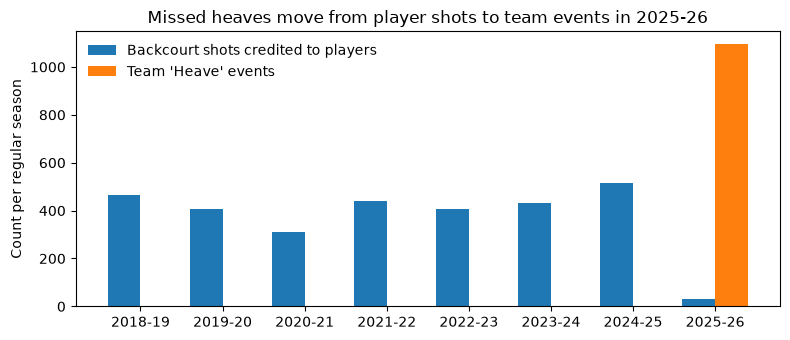

In [4]:
rs = checks[checks.season_type == "Regular Season"]
fig, ax = plt.subplots(figsize=(8, 3.5))
x = range(len(rs))
ax.bar([i - 0.2 for i in x], rs.backcourt_shots, width=0.4, label="Backcourt shots credited to players")
ax.bar([i + 0.2 for i in x], rs.pbp_team_heave_events, width=0.4, label="Team 'Heave' events")
ax.set_xticks(list(x), rs.season)
ax.set_ylabel("Count per regular season")
ax.set_title("Missed heaves move from player shots to team events in 2025-26")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "stage3_heaves.png", dpi=150)

## 4. Structural cleaning and attrition

Cleaning only fixes structure: duplicates, types, column names, the clock parsed to seconds,
season labels, and the join to play-by-play (for the precise clock, the chronological position and
the score before each shot). No shot is excluded for looking unusual.

In [5]:
# Hashes recorded by the previous run (committed with the repo), read before overwriting
expected = (pd.read_csv(clean.ATTRITION).dropna(subset=["content_hash"])
            .set_index(["season", "season_type"]).content_hash)
attrition = clean.run()
attrition.pivot_table(index=["season", "season_type"], columns="rule", values="rows_after",
                      sort=False).astype(int)

rule                       raw  drop exact duplicate rows  drop duplicate game/event/player keys  drop shots with no play-by-play event for the same player
season  season_type                                                                                                                                        
2018-19 Regular Season  219458                     219458                                 219458                                             219458        
        Playoffs         14259                      14259                                  14259                                              14259        
2019-20 Regular Season  188116                     188116                                 188116                                             188116        
        Playoffs         14107                      14107                                  14107                                              14107        
2020-21 Regular Season  190983                     190983                                 190983                                             190983        
        Playoffs         14771                      14771                                  14771                                              14771        
2021-22 Regular Season  216722                     216722                                 216722                                             216722        
        Playoffs         14571                      14571                                  14571                                              14571        
2022-23 Regular Season  217218                     217218                                 217218                                             217216        
        Playoffs         14651                      14651                                  14651                                              14651        
2023-24 Regular Season  218701                     218701                                 218701                                             218700        
        Playoffs         13840                      13840                                  13840                                              13840        
2024-25 Regular Season  219527                     219527                                 219527                                             219526        
        Playoffs         14377                      14377                                  14377                                              14377        
2025-26 Regular Season  219160                     219160                                 219160                                             219156        
        Playoffs         14473                      14473                                  14473                                              14473

## 5. Reproducibility check

Re-running cleaning from raw data must reproduce the cleaned files exactly. Each cleaned table has a
content hash (independent of parquet metadata); the expected hashes are read from the committed
`reports/stage3_attrition.csv` before this run overwrites it.

In [6]:
final = attrition.groupby(["season", "season_type"], sort=False).last()
same = (final.content_hash == expected.reindex(final.index))
assert same.all(), f"cleaned files differ from the previous run: {list(same[~same].index)}"
print(f"All {len(same)} cleaned files reproduce the content hashes of the previous run.")

All 16 cleaned files reproduce the content hashes of the previous run.


## 6. Write the data-quality report

In [7]:
ok = audit.write_report(checks, schema, attrition)
print("Automated checks:", "all pass or documented" if ok else "FAILURES", "(gate declared by Massimo)")
assert ok

Automated checks: all pass or documented (gate declared by Massimo)
